In [ ]:
%pip install -q tensorflow keras numpy pydot

Note: you may need to restart the kernel to use updated packages.


# Deep Learning for image classification
### Amir, 2025, NUS SoC ACE

#### We'll try to classify images of pets into 2 classes, Cats and Dogs
#### We compute and report the classification accuracy
#### Images are in $ petsmaller$ folder. they are color and 180x180 pixels

In [18]:
import tensorflow as tf
import keras
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

In [19]:
# # mounting the Google drive
# from google.colab import drive

# drive.mount('/content/drive')

# # Load the dataset
# fp = "/content/drive/My Drive/emeritus/2025/Module2-3/petsmaller"

fp = "petsmaller"

In [20]:
if tf.test.gpu_device_name():
    print('Default GPU Device: {}'.format(tf.test.gpu_device_name()))
else:
   print("Please install GPU version of TF")

Please install GPU version of TF


In [21]:
# setting the train and evaluation dataset and directories

In [22]:
image_size = (180, 180)
batch_size = 16

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    fp,
    validation_split=0.2,
    subset="training",
    seed=1337,
    image_size=image_size,
    batch_size=batch_size,
)
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    fp,
    validation_split=0.2,
    subset="validation",
    seed=1337,
    image_size=image_size,
    batch_size=batch_size,
)

Found 7493 files belonging to 2 classes.
Using 5995 files for training.
Found 7493 files belonging to 2 classes.
Using 1498 files for validation.


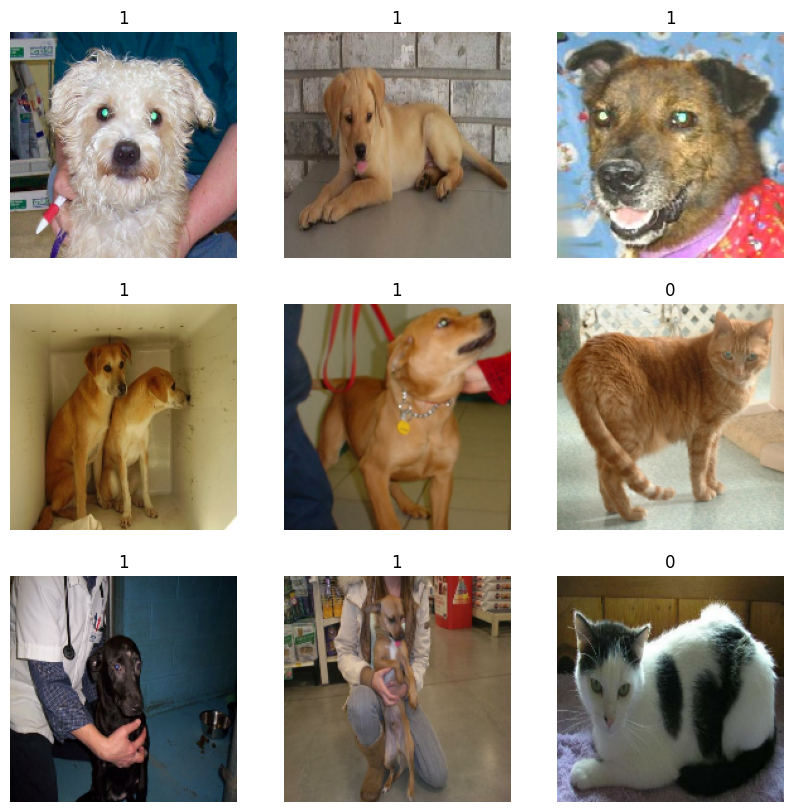

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(int(labels[i]))
        plt.axis("off")

In [24]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
    ]
)

2025-07-27 23:08:24.811244: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


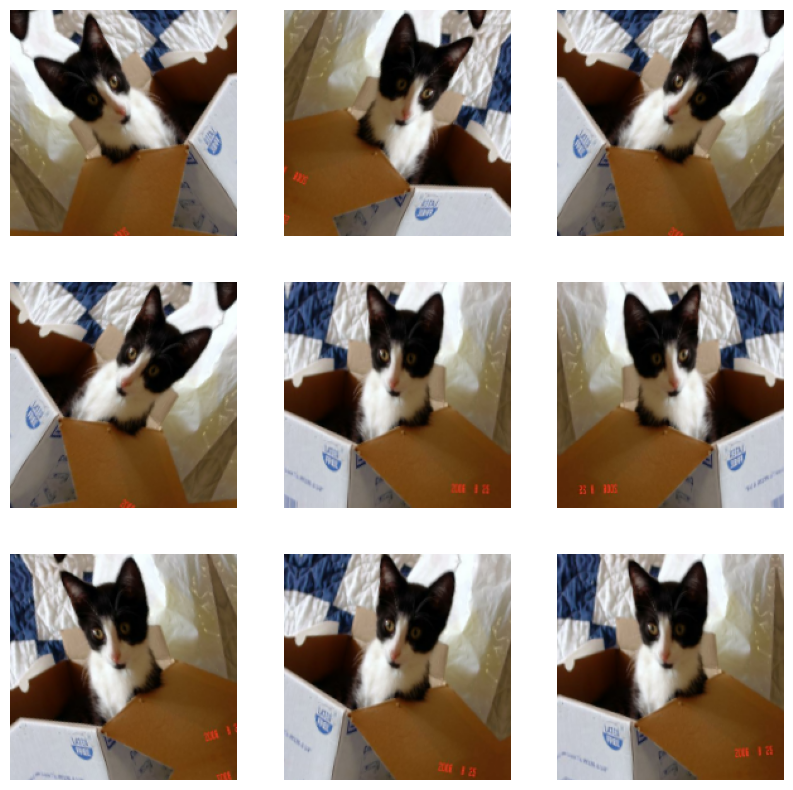

In [25]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(augmented_images[0].numpy().astype("uint8"))
        plt.axis("off")

In [26]:
augmented_train_ds = train_ds.map(
  lambda x, y: (data_augmentation(x, training=True), y))

In [27]:
train_ds = train_ds.prefetch(buffer_size=32)
val_ds = val_ds.prefetch(buffer_size=32)

In [28]:
# making our deep model

In [29]:
def make_model(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)
    # Image augmentation block
    x = data_augmentation(inputs)

    # Entry block
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(32, 3, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(64, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x  # Set aside residual

    for size in [128, 256, 512, 728]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        # Project residual
        residual = layers.Conv2D(size, 1, strides=2, padding="same")(
            previous_block_activation
        )
        x = layers.add([x, residual])  # Add back residual
        previous_block_activation = x  # Set aside next residual

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    if num_classes == 2:
        activation = "sigmoid"
        units = 1
    else:
        activation = "softmax"
        units = num_classes

    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(units, activation=activation)(x)
    return keras.Model(inputs, outputs)

In [31]:
model = make_model(input_shape=image_size + (3,), num_classes=2)
keras.utils.plot_model(model, show_shapes=True)

In [14]:
# compiling and training our model

In [32]:
epochs = 30

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    train_ds, epochs=epochs, validation_data=val_ds,
)

Epoch 1/30
 32/375 ━━━━━━━━━━━━━━━━━━━━ 1:38 286ms/step - accuracy: 0.5575 - loss: 0.8113

Corrupt JPEG data: 228 extraneous bytes before marker 0xd9


212/375 ━━━━━━━━━━━━━━━━━━━━ 48s 297ms/step - accuracy: 0.5659 - loss: 0.7709

Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


287/375 ━━━━━━━━━━━━━━━━━━━━ 26s 296ms/step - accuracy: 0.5717 - loss: 0.7588

...

205/375 ━━━━━━━━━━━━━━━━━━━━ 52s 310ms/step - accuracy: 0.9378 - loss: 0.1604

Corrupt JPEG data: 214 extraneous bytes before marker 0xd9


273/375 ━━━━━━━━━━━━━━━━━━━━ 31s 313ms/step - accuracy: 0.9363 - loss: 0.1624

Corrupt JPEG data: 128 extraneous bytes before marker 0xd9


375/375 ━━━━━━━━━━━━━━━━━━━━ 125s 333ms/step - accuracy: 0.9347 - loss: 0.1645 - val_accuracy: 0.9292 - val_loss: 0.1753


In [ ]:
# above: the last validation accuracy above, is a good metric
# to show your classifier performance
# below: testing the classifier with some images

In [33]:
img = keras.preprocessing.image.load_img( fp+"/Cat/0.jpg" , target_size=image_size )
img_array = keras.preprocessing.image.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create batch axis

predictions = model.predict(img_array)
score = predictions[0]
print(
    "This image is %.2f percent cat and %.2f percent dog."
    % (100 * (1 - score), 100 * score)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
This image is 97.39 percent cat and 2.61 percent dog.


/var/folders/5t/yhw_yxtj4hd3cl86y215nn0h0000gn/T/ipykernel_37834/2192209314.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "This image is %.2f percent cat and %.2f percent dog."


In [34]:
img = keras.preprocessing.image.load_img( fp+ "/Dog/4.jpg" , target_size=image_size )
img_array = keras.preprocessing.image.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create batch axis

predictions = model.predict(img_array)
score = predictions[0]
print(
    "This image is %.2f percent cat and %.2f percent dog."
    % (100 * (1 - score), 100 * score)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
This image is 0.00 percent cat and 100.00 percent dog.


/var/folders/5t/yhw_yxtj4hd3cl86y215nn0h0000gn/T/ipykernel_37834/2296512599.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "This image is %.2f percent cat and %.2f percent dog."


In [35]:
img = keras.preprocessing.image.load_img( fp+"/Dog/31.jpg", target_size=image_size )
img_array = keras.preprocessing.image.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create batch axis

predictions = model.predict(img_array)
score = predictions[0]
print(
    "This image is %.2f percent cat and %.2f percent dog."
    % (100 * (1 - score), 100 * score)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
This image is 0.47 percent cat and 99.53 percent dog.


/var/folders/5t/yhw_yxtj4hd3cl86y215nn0h0000gn/T/ipykernel_37834/696025786.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "This image is %.2f percent cat and %.2f percent dog."


In [39]:
#
# the list of test files is in flst.txt, you may need to change the path
# predict() function is employed , each test image is preprocessed the way train images had been
#
fp= "flst.txt"
# Open and read the file list
with open(fp, "r") as f:
    filenames = f.read().splitlines()  # Read all lines and remove newline characters

# Process each file
predct = []
for i in filenames:
    #i = i.decode('utf-8')
    img = keras.preprocessing.image.load_img( i , target_size=image_size )
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # Create batch axis

    predictions = model.predict(img_array, verbose=0)
    score = predictions[0]
    print( i ,
        " is %.2f percent cat and %.2f percent dog."
        % (100 * (1 - score), 100 * score)
    )
    predct.append( np.round(score) )


/var/folders/5t/yhw_yxtj4hd3cl86y215nn0h0000gn/T/ipykernel_37834/605532864.py:21: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  " is %.2f percent cat and %.2f percent dog."


petsmaller/Cat/0.jpg  is 97.39 percent cat and 2.61 percent dog.
petsmaller/Cat/1.jpg  is 99.93 percent cat and 0.07 percent dog.
petsmaller/Cat/10.jpg  is 99.75 percent cat and 0.25 percent dog.
petsmaller/Cat/13.jpg  is 98.84 percent cat and 1.16 percent dog.
petsmaller/Cat/14.jpg  is 99.98 percent cat and 0.02 percent dog.
petsmaller/Cat/15.jpg  is 98.05 percent cat and 1.95 percent dog.
petsmaller/Cat/16.jpg  is 86.62 percent cat and 13.38 percent dog.
petsmaller/Cat/17.jpg  is 99.15 percent cat and 0.85 percent dog.
petsmaller/Cat/4.jpg  is 98.42 percent cat and 1.58 percent dog.
petsmaller/Cat/5.jpg  is 47.71 percent cat and 52.29 percent dog.
petsmaller/Cat/6.jpg  is 17.24 percent cat and 82.76 percent dog.
petsmaller/Cat/7.jpg  is 99.95 percent cat and 0.05 percent dog.
petsmaller/Cat/8.jpg  is 99.88 percent cat and 0.12 percent dog.
petsmaller/Cat/9.jpg  is 99.39 percent cat and 0.61 percent dog.
petsmaller/Dog/16.jpg  is 0.25 percent cat and 99.75 percent dog.
petsmaller/Dog/

In [40]:
print('Predictions: ')
for j in range(len (predct)):
  print(predct[j])


Predictions: 
[0.]
[0.]
[0.]
[0.]
[0.]
[0.]
[0.]
[0.]
[0.]
[1.]
[1.]
[0.]
[0.]
[0.]
[1.]
[1.]
[0.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]
[1.]


##  Practices
1. train the model for 5, 10, and 80 epochs. what are the evaluation results?
2. set back everything to the original setting, then try delete some of the convolutional and downsampling layers and train the model again. What will be the evaluation results?
3. Deep convolutional model used here is a modified Xception (Extreme Inception). Can you change the make_model() function and use other known deep convolutional models like Alexnet or VGG-16? Try that and see the results.

#### points:
- use GPU as your runtime type
